In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import joblib

In [2]:
PROJECT_DIR = Path.cwd().parent
DATA_DIR = PROJECT_DIR / "data" / "raw" / "privacy_reviews"

train = pd.read_csv(DATA_DIR / "original_12756.csv")
val = pd.read_csv(DATA_DIR / "val_1595.csv")
test = pd.read_csv(DATA_DIR / "test_1594.csv")

print("Training:", train.shape)
print("Validation:", val.shape)
print("Test:", test.shape)

Training: (12756, 3)
Validation: (1595, 3)
Test: (1594, 3)


In [3]:
# Training data
X_train = train["Review"]
y_train = train["Label"]

# Validation data
X_val = val["Review"]
y_val = val["Label"]

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Classes:", sorted(y_train.unique()))

Training samples: 12756
Validation samples: 1595
Classes: [np.int64(0), np.int64(1), np.int64(2)]


In [4]:
# Naive Bayes pipeline
nb_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=10000,
        ngram_range=(1, 2),
        min_df=2,
        sublinear_tf=True
    )),
    ("classifier", MultinomialNB(alpha=1.0))
])

# Random Forest pipeline
rf_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=10000,
        ngram_range=(1, 2),
        min_df=2,
        sublinear_tf=True
    )),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

print("Both pipelines created successfully!")

Both pipelines created successfully!


In [5]:
print("Training Naive Bayes...")
nb_pipeline.fit(X_train, y_train)
print("Naive Bayes completed!")

print("\nTraining Random Forest...")
rf_pipeline.fit(X_train, y_train)
print("Random Forest completed!")

Training Naive Bayes...
Naive Bayes completed!

Training Random Forest...
Random Forest completed!


In [6]:
# Generate predictions on validation data
nb_val_pred = nb_pipeline.predict(X_val)
rf_val_pred = rf_pipeline.predict(X_val)

print("Both validation predictions generated successfully!")

Both validation predictions generated successfully!


In [7]:
comparison_results = []

models = {
    "Naive Bayes": nb_val_pred,
    "Random Forest": rf_val_pred
}

for model_name, predictions in models.items():

    comparison_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision (Macro)": precision_score(
            y_val, predictions, average="macro"
        ),
        "Recall (Macro)": recall_score(
            y_val, predictions, average="macro"
        ),
        "F1-Score (Macro)": f1_score(
            y_val, predictions, average="macro"
        )
    })

comparison_df = pd.DataFrame(comparison_results)

print("MODEL COMPARISON - VALIDATION RESULTS")
display(
    comparison_df.round(4).set_index("Model")
)

MODEL COMPARISON - VALIDATION RESULTS


,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro)
Model,,,,
Naive Bayes,0.8439,0.8424,0.8195,0.8296
Random Forest,0.8464,0.8364,0.8327,0.8344


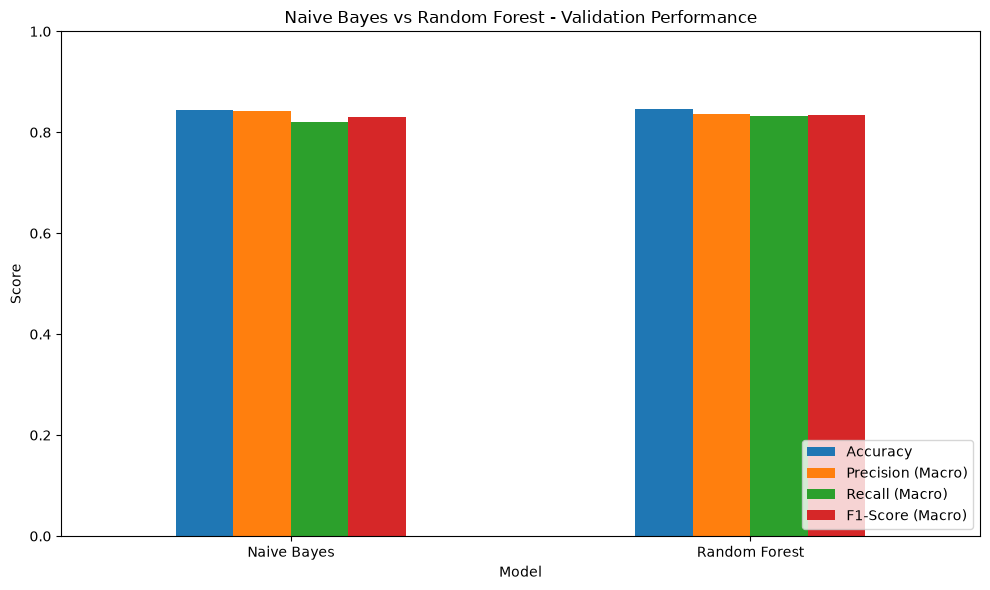

In [8]:
metrics = [
    "Accuracy",
    "Precision (Macro)",
    "Recall (Macro)",
    "F1-Score (Macro)"
]

comparison_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1),
    rot=0
)

plt.title("Naive Bayes vs Random Forest - Validation Performance")
plt.ylabel("Score")
plt.xlabel("Model")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [9]:
# Select Random Forest as the final model
best_model = rf_pipeline

print("Selected model: Random Forest")
print("Validation accuracy:",
      round(accuracy_score(y_val, best_model.predict(X_val)) * 100, 2), "%")

Selected model: Random Forest
Validation accuracy: 84.64 %


In [10]:
# Preparing the untouched test data
X_test = test["Review"]
y_test = test["Label"]

# Final predictions
y_test_pred = best_model.predict(X_test)

# Calculate final metrics
print("FINAL RANDOM FOREST TEST RESULTS")
print("=" * 45)

print(
    "Test Accuracy:",
    round(accuracy_score(y_test, y_test_pred) * 100, 2),
    "%"
)

print(
    "Macro Precision:",
    round(precision_score(y_test, y_test_pred, average="macro"), 4)
)

print(
    "Macro Recall:",
    round(recall_score(y_test, y_test_pred, average="macro"), 4)
)

print(
    "Macro F1-score:",
    round(f1_score(y_test, y_test_pred, average="macro"), 4)
)

print("\nClassification Report:\n")

print(classification_report(
    y_test,
    y_test_pred,
    labels=[0, 1, 2],
    target_names=[
        "Feature Request",
        "Bug Report",
        "Privacy-Irrelevant"
    ],
    zero_division=0
))

FINAL RANDOM FOREST TEST RESULTS
Test Accuracy: 83.19 %
Macro Precision: 0.8202
Macro Recall: 0.8112
Macro F1-score: 0.8152

Classification Report:

                    precision    recall  f1-score   support

   Feature Request       0.82      0.75      0.79       359
        Bug Report       0.77      0.79      0.78       420
Privacy-Irrelevant       0.87      0.89      0.88       815

          accuracy                           0.83      1594
         macro avg       0.82      0.81      0.82      1594
      weighted avg       0.83      0.83      0.83      1594



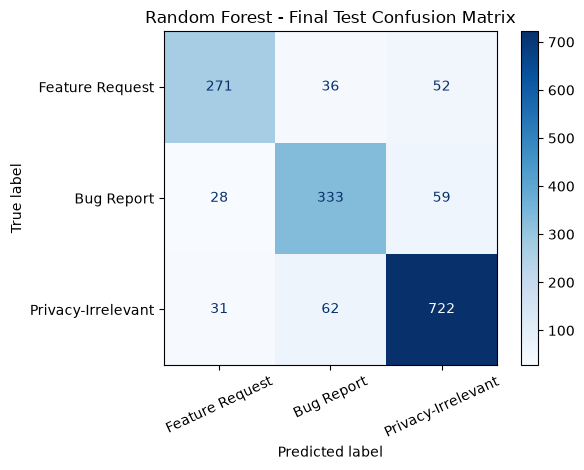

In [11]:
cm_test = confusion_matrix(
    y_test,
    y_test_pred,
    labels=[0, 1, 2]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_test,
    display_labels=[
        "Feature Request",
        "Bug Report",
        "Privacy-Irrelevant"
    ]
)

disp.plot(cmap="Blues", xticks_rotation=25)

plt.title("Random Forest - Final Test Confusion Matrix")
plt.tight_layout()
plt.show()

## Final Model Evaluation – Random Forest

### Dataset
- Training samples: 12,756
- Validation samples: 1,595
- Test samples: 1,594
- Input feature: Review
- Feature extraction: TF-IDF
- Classifier: Random Forest
- Number of estimators: 200

### Validation Performance
- Accuracy: 84.64%
- Macro Precision: 0.8364
- Macro Recall: 0.8327
- Macro F1-score: 0.8344

### Final Test Performance
- Accuracy: 83.19%
- Macro Precision: 0.8202
- Macro Recall: 0.8112
- Macro F1-score: 0.8152

### Conclusion

Random Forest was selected based on its validation performance, achieving the highest validation accuracy and macro F1-score among the two evaluated models.

On the independent test dataset, it achieved 83.19% accuracy and a macro F1-score of 0.8152.

The model performed best on the Privacy-Irrelevant category, while Feature Request and Bug Report classification leave scope for further improvement.

These results demonstrate the feasibility of classifying privacy-related social-media reviews using TF-IDF and Random Forest.

In [12]:
# Saving trained model
MODEL_DIR = PROJECT_DIR / "models"

# Save the complete trained pipeline
model_path = MODEL_DIR / "forcora_random_forest.joblib"

joblib.dump(best_model, model_path)

print("Model saved successfully!")
print("Location:", model_path)

Model saved successfully!
Location: d:\MINOR\forcora\models\forcora_random_forest.joblib


In [13]:
# Load the saved model
loaded_model = joblib.load(model_path)

# Try predicting new customer reviews
sample_reviews = [
    "The app crashes whenever I open privacy settings",
    "Please add an option to hide my online status",
    "I enjoy using this application"
]

predictions = loaded_model.predict(sample_reviews)

label_map = {
    0: "Feature Request",
    1: "Bug Report",
    2: "Privacy-Irrelevant"
}

for review, prediction in zip(sample_reviews, predictions):
    print("Review:", review)
    print("Predicted category:", label_map[prediction])
    print("-" * 60)

Review: The app crashes whenever I open privacy settings
Predicted category: Privacy-Irrelevant
------------------------------------------------------------
Review: Please add an option to hide my online status
Predicted category: Feature Request
------------------------------------------------------------
Review: I enjoy using this application
Predicted category: Privacy-Irrelevant
------------------------------------------------------------


In [14]:
# Examine prediction probabilities
probabilities = loaded_model.predict_proba(sample_reviews)

for review, prediction, probs in zip(
    sample_reviews, predictions, probabilities
):
    print("\nReview:", review)
    print("Predicted:", label_map[prediction])

    for class_id, probability in enumerate(probs):
        print(
            f"{label_map[class_id]}: {probability:.4f}"
        )


Review: The app crashes whenever I open privacy settings
Predicted: Privacy-Irrelevant
Feature Request: 0.2550
Bug Report: 0.3350
Privacy-Irrelevant: 0.4100

Review: Please add an option to hide my online status
Predicted: Feature Request
Feature Request: 0.7750
Bug Report: 0.0250
Privacy-Irrelevant: 0.2000

Review: I enjoy using this application
Predicted: Privacy-Irrelevant
Feature Request: 0.0450
Bug Report: 0.0300
Privacy-Irrelevant: 0.9250
